# Preliminary EDA — phone / watch accel & gyro

Dataset layout: `raw/{phone,watch}/{accel,gyro}/data_{subject}_{sensor}_{device}.txt`  
Line format: `subject,activity,timestamp,x,y,z;`

This notebook streams files once (data is ~850MB) and produces:
1. Duplicate-row audit
2. Coverage & balance tables
3. Sampling-rate / gap estimates
4. Signal magnitude boxplots by activity
5. Short time-series snippets for a few activities
6. Spectral analysis (Welch PSD, dominant frequency, spectrograms)


In [20]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path(".").resolve()
RAW = ROOT / "raw"
ACTIVITY_MAP = json.loads((ROOT / "activity_map.json").read_text())["ACTIVITY_MAP"]
ACTIVITY_ORDER = list(ACTIVITY_MAP.keys())

STREAMS = [
    ("phone", "accel"),
    ("phone", "gyro"),
    ("watch", "accel"),
    ("watch", "gyro"),
]

print(f"Project root: {ROOT}")
print(f"Activities ({len(ACTIVITY_MAP)}): {ACTIVITY_MAP}")

Project root: /Users/tomhait/git/tom.aharon-hait/projects/mini_project
Activities (18): {'A': 'Walking', 'B': 'Jogging', 'C': 'Stairs', 'D': 'Sitting', 'E': 'Standing', 'F': 'Typing', 'G': 'Brushing Teeth', 'H': 'Eating Soup', 'I': 'Eating Chips', 'J': 'Eating Pasta', 'K': 'Drinking from Cup', 'L': 'Eating Sandwich', 'M': 'Kicking Soccer Ball', 'O': 'Playing Catch', 'P': 'Dribbling Basketball', 'Q': 'Writing', 'R': 'Clapping', 'S': 'Folding Clothes'}


## Helpers

Parsers strip the trailing `;`. Timestamps are treated as device elapsed time in nanoseconds.

In [21]:
def list_stream_files(device: str, sensor: str) -> list[Path]:
    return sorted((RAW / device / sensor).glob(f"data_*_{sensor}_{device}.txt"))


def parse_subject_from_name(path: Path) -> int:
    # data_1600_accel_phone.txt
    return int(path.name.split("_")[1])


def read_sensor_file(path: Path) -> pd.DataFrame:
    """Load one raw sensor file into a clean DataFrame."""
    df = pd.read_csv(
        path,
        header=None,
        names=["subject", "activity", "timestamp", "x", "y", "z"],
        dtype={
            "subject": "int32",
            "activity": "string",
            "timestamp": "int64",
            "x": "float64",
            "y": "float64",
        },
        converters={"z": lambda v: float(str(v).rstrip(";"))},
    )
    df["z"] = df["z"].astype("float64")
    return df


def activity_label(code: str) -> str:
    return f"{code}: {ACTIVITY_MAP.get(code, '?')}"


def estimate_hz(timestamps_ns: np.ndarray) -> dict:
    """Median / mean Hz and gap stats from sorted timestamps (ns)."""
    if len(timestamps_ns) < 2:
        return {
            "n": len(timestamps_ns),
            "median_hz": np.nan,
            "mean_hz": np.nan,
            "p99_dt_ms": np.nan,
            "gap_gt_0_5s": 0,
            "duration_s": 0.0,
            "non_monotonic": 0,
        }
    ts = np.asarray(timestamps_ns, dtype=np.int64)
    # keep order as recorded; flag non-monotonic separately if needed
    dt = np.diff(ts.astype(np.float64))
    positive = dt[dt > 0]
    if positive.size == 0:
        median_hz = mean_hz = p99_dt_ms = np.nan
        gaps = 0
    else:
        median_hz = 1e9 / np.median(positive)
        mean_hz = 1e9 / np.mean(positive)
        p99_dt_ms = np.percentile(positive, 99) / 1e6
        gaps = int((positive > 0.5e9).sum())
    duration_s = float((ts[-1] - ts[0]) / 1e9) if ts[-1] > ts[0] else 0.0
    return {
        "n": int(len(ts)),
        "median_hz": float(median_hz),
        "mean_hz": float(mean_hz),
        "p99_dt_ms": float(p99_dt_ms),
        "gap_gt_0_5s": gaps,
        "duration_s": duration_s,
        "non_monotonic": int((dt <= 0).sum()),
    }

## 1. Duplicate row audit

Check every raw file for:
- **full-row duplicates** (`subject, activity, timestamp, x, y, z`)
- **repeated timestamps** (same clock tick more than once)

Known issues from a prior full scan: subject **1629** files are exact doubles; subject **1649** watch streams have some timestamp collisions across activity labels.


In [22]:
dup_rows = []

all_files = [(d, s, p) for d, s in STREAMS for p in list_stream_files(d, s)]
print(f"Scanning {len(all_files)} files for duplicates...")

for device, sensor, path in tqdm(all_files, desc="Duplicate audit"):
    subject = parse_subject_from_name(path)
    df = read_sensor_file(path)
    n = len(df)
    full_extra = int(df.duplicated().sum())
    full_involved = int(df.duplicated(keep=False).sum())
    ts_extra = int(df["timestamp"].duplicated().sum())
    ts_involved = int(df["timestamp"].duplicated(keep=False).sum())
    act_ts_extra = int(df.duplicated(subset=["activity", "timestamp"]).sum())

    # exact concatenation double? (first half == second half)
    exact_half_double = False
    if n >= 2 and n % 2 == 0:
        half = n // 2
        exact_half_double = df.iloc[:half].reset_index(drop=True).equals(
            df.iloc[half:].reset_index(drop=True)
        )

    dup_rows.append(
        {
            "device": device,
            "sensor": sensor,
            "subject": subject,
            "n_rows": n,
            "n_unique_rows": int(len(df.drop_duplicates())),
            "full_row_extra": full_extra,
            "full_row_involved": full_involved,
            "timestamp_extra": ts_extra,
            "timestamp_involved": ts_involved,
            "activity_timestamp_extra": act_ts_extra,
            "exact_half_double": exact_half_double,
        }
    )

dup_audit = pd.DataFrame(dup_rows).sort_values(
    ["full_row_extra", "timestamp_extra"], ascending=False
).reset_index(drop=True)

issues = dup_audit.query(
    "full_row_extra > 0 or timestamp_extra > 0 or activity_timestamp_extra > 0"
)
print(f"Files with any duplicate issue: {len(issues)} / {len(dup_audit)}")
if issues.empty:
    print("No duplicate rows or repeated timestamps found.")
else:
    display(issues)
    print("\nTotals by stream:")
    display(
        issues.groupby(["device", "sensor"], as_index=False)[
            ["full_row_extra", "timestamp_extra", "activity_timestamp_extra"]
        ].sum()
    )
    if issues["exact_half_double"].any():
        print("\nExact half-file duplicates (concatenated twice):")
        display(issues.loc[issues["exact_half_double"], ["device", "sensor", "subject", "n_rows", "n_unique_rows"]])

# Optional cleanup helper for later cells / modeling
def drop_file_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    """Remove exact duplicate rows (keeps first occurrence)."""
    return df.drop_duplicates().reset_index(drop=True)


Scanning 204 files for duplicates...


Duplicate audit:   0%|          | 0/204 [00:00<?, ?it/s]

Files with any duplicate issue: 6 / 204


,device,sensor,subject,n_rows,n_unique_rows,full_row_extra,full_row_involved,timestamp_extra,timestamp_involved,activity_timestamp_extra,exact_half_double
0,phone,accel,1629,139346,69673,69673,139346,69673,139346,69673,True
1,watch,accel,1629,129808,64904,64904,129808,64904,129808,64904,True
2,watch,gyro,1629,129738,64869,64869,129738,64869,129738,64869,True
3,phone,gyro,1629,128500,64250,64250,128500,64250,128500,64250,True
4,watch,accel,1649,65166,65166,0,0,1160,2320,0,False
5,watch,gyro,1649,65131,65131,0,0,1159,2318,0,False



Totals by stream:


,device,sensor,full_row_extra,timestamp_extra,activity_timestamp_extra
0,phone,accel,69673,69673,69673
1,phone,gyro,64250,64250,64250
2,watch,accel,64904,66064,64904
3,watch,gyro,64869,66028,64869



Exact half-file duplicates (concatenated twice):


,device,sensor,subject,n_rows,n_unique_rows
0,phone,accel,1629,139346,69673
1,watch,accel,1629,129808,64904
2,watch,gyro,1629,129738,64869
3,phone,gyro,1629,128500,64250


## 2. Stream pass — coverage, sampling, magnitude samples

One pass over all files builds lightweight tables used below. Magnitude samples are capped per (stream, activity) for plotting.

In [23]:
MAX_MAG_SAMPLES_PER_ACTIVITY = 4000  # per device×sensor×activity
rng = np.random.default_rng(42)

file_rows = []
activity_rows = []
mag_samples = []  # list of small frames, concatenated at end

all_files = [(d, s, p) for d, s in STREAMS for p in list_stream_files(d, s)]
print(f"Files found: {len(all_files)}")

for device, sensor, path in tqdm(all_files, desc="Scanning sensor files"):
    subject = parse_subject_from_name(path)
    df = read_sensor_file(path)

    # file-level sampling stats
    hz = estimate_hz(df["timestamp"].to_numpy())
    file_rows.append(
        {
            "device": device,
            "sensor": sensor,
            "subject": subject,
            "n_rows": len(df),
            "n_activities": df["activity"].nunique(),
            "activities": "".join(sorted(df["activity"].unique())),
            **hz,
            "n_nan": int(df[["x", "y", "z"]].isna().any(axis=1).sum()),
            "n_inf": int(np.isinf(df[["x", "y", "z"]].to_numpy()).any(axis=1).sum()),
        }
    )

    df = df.copy()
    df["mag"] = np.sqrt(df["x"] ** 2 + df["y"] ** 2 + df["z"] ** 2)

    for act, g in df.groupby("activity", sort=False):
        activity_rows.append(
            {
                "device": device,
                "sensor": sensor,
                "subject": subject,
                "activity": act,
                "n": len(g),
                "duration_s": estimate_hz(g["timestamp"].to_numpy())["duration_s"],
                "mag_mean": float(g["mag"].mean()),
                "mag_std": float(g["mag"].std(ddof=0)),
                "mag_median": float(g["mag"].median()),
            }
        )

        # Per-file subsample; final per-(stream, activity) cap applied after concat.
        idx = rng.choice(len(g), size=min(200, len(g)), replace=False)
        sample = g.iloc[idx][["activity", "mag"]].copy()
        sample["device"] = device
        sample["sensor"] = sensor
        sample["subject"] = subject
        mag_samples.append(sample)

files = pd.DataFrame(file_rows).sort_values(["device", "sensor", "subject"]).reset_index(drop=True)
act_subj = pd.DataFrame(activity_rows)
mags = pd.concat(mag_samples, ignore_index=True)

# final per-(stream, activity) downsample for boxplots
parts = []
for _, g in mags.groupby(["device", "sensor", "activity"], sort=False):
    parts.append(g.sample(n=min(len(g), MAX_MAG_SAMPLES_PER_ACTIVITY), random_state=42))
mags_plot = pd.concat(parts, ignore_index=True)
mags_plot["activity_name"] = mags_plot["activity"].map(ACTIVITY_MAP)
act_subj["activity_name"] = act_subj["activity"].map(ACTIVITY_MAP)

print(files.groupby(["device", "sensor"]).size().rename("n_files").to_frame())
print(f"\nMagnitude plot sample rows: {len(mags_plot):,}")

Files found: 204


Scanning sensor files:   0%|          | 0/204 [00:00<?, ?it/s]

               n_files
device sensor         
phone  accel        51
       gyro         51
watch  accel        51
       gyro         51

Magnitude plot sample rows: 288,000


## 3. Coverage & balance

In [24]:
subjects_by_stream = (
    files.groupby(["device", "sensor"])["subject"]
    .agg(n_subjects="nunique", subjects=lambda s: sorted(s.unique()))
    .reset_index()
)
display(subjects_by_stream.drop(columns=["subjects"]))

all_subjects = sorted(files["subject"].unique())
print(f"Unique subjects overall: {len(all_subjects)} — {all_subjects[0]}…{all_subjects[-1]}")

# which subjects miss a stream?
pivot_presence = (
    files.assign(present=1)
    .pivot_table(index="subject", columns=["device", "sensor"], values="present", fill_value=0)
)
missing = pivot_presence.loc[pivot_presence.min(axis=1) == 0]
if missing.empty:
    print("Every subject has all 4 streams.")
else:
    print("Subjects missing at least one stream:")
    display(missing)

,device,sensor,n_subjects
0,phone,accel,51
1,phone,gyro,51
2,watch,accel,51
3,watch,gyro,51


Unique subjects overall: 51 — 1600…1650
Every subject has all 4 streams.


Sample counts by activity (phone accel):


,activity,activity_name,n_samples,total_duration_s,n_subjects
0,A,Walking,279817,9178.784007,51
1,B,Jogging,268409,8818.536565,49
2,C,Stairs,255645,8997.851909,50
3,D,Sitting,264592,9177.891512,51
4,E,Standing,269604,9178.298155,51
5,F,Typing,246356,8815.973741,49
6,G,Brushing Teeth,269609,9177.865905,51
7,H,Eating Soup,270756,9177.541203,51
8,I,Eating Chips,261360,8997.918583,50
9,J,Eating Pasta,249793,8996.200218,50


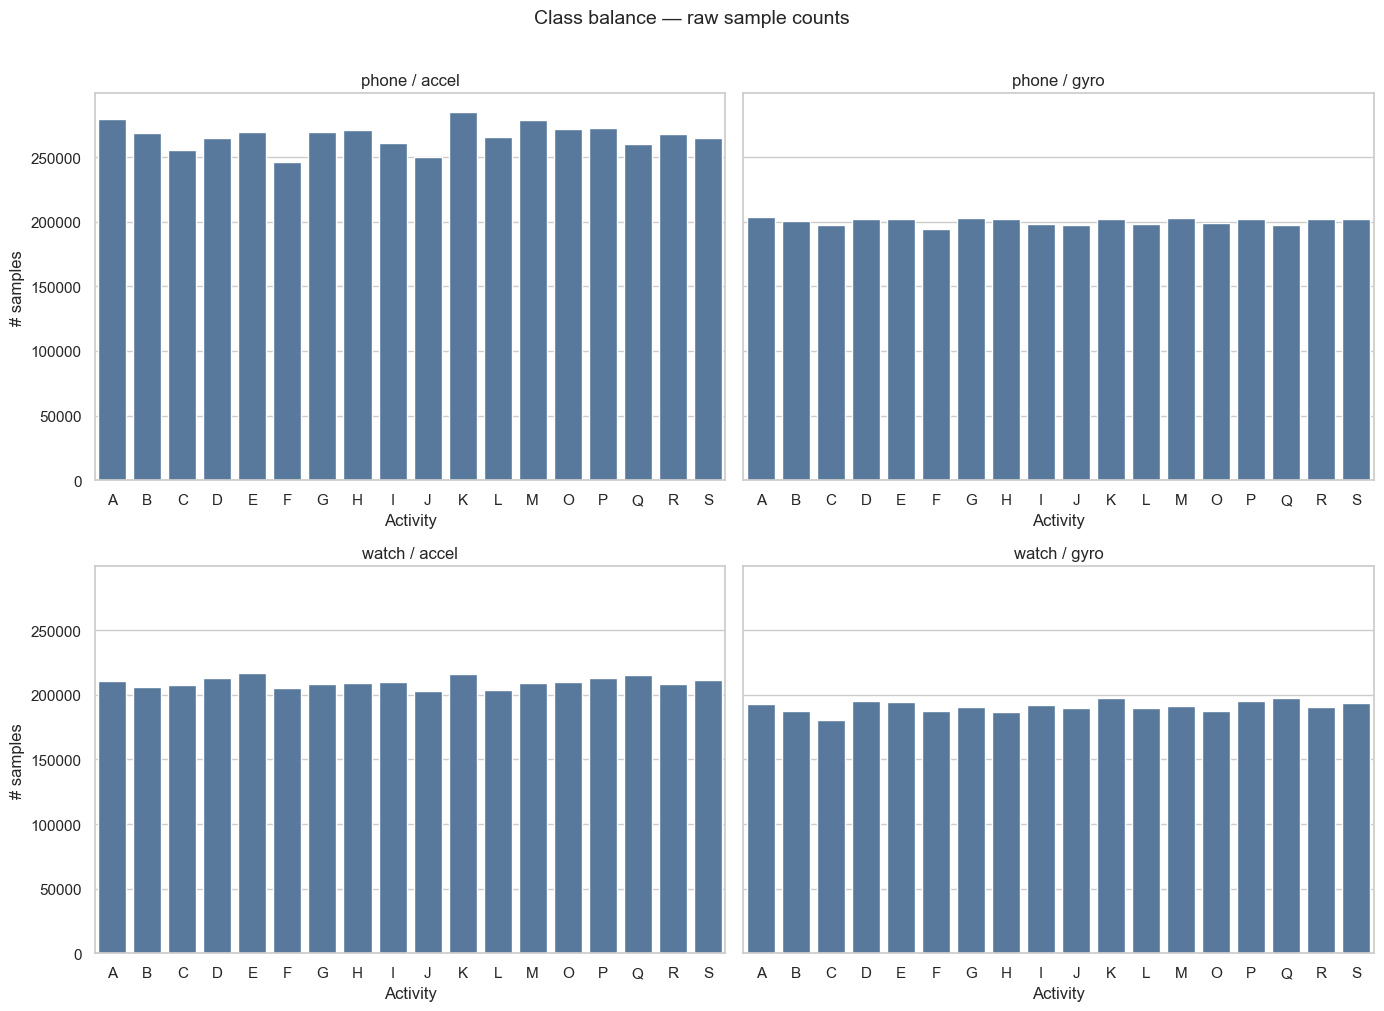

In [25]:
# sample / duration counts by activity × stream
activity_totals = (
    act_subj.groupby(["device", "sensor", "activity", "activity_name"], as_index=False)
    .agg(n_samples=("n", "sum"), total_duration_s=("duration_s", "sum"), n_subjects=("subject", "nunique"))
    .sort_values(["device", "sensor", "activity"])
)

print("Sample counts by activity (phone accel):")
display(
    activity_totals.query("device == 'phone' and sensor == 'accel'")[
        ["activity", "activity_name", "n_samples", "total_duration_s", "n_subjects"]
    ]
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
for ax, (device, sensor) in zip(axes.ravel(), STREAMS):
    sub = activity_totals.query("device == @device and sensor == @sensor").copy()
    sub["activity"] = pd.Categorical(sub["activity"], categories=ACTIVITY_ORDER, ordered=True)
    sub = sub.sort_values("activity")
    sns.barplot(data=sub, x="activity", y="n_samples", ax=ax, color="#4C78A8")
    ax.set_title(f"{device} / {sensor}")
    ax.set_xlabel("Activity")
    ax.set_ylabel("# samples")
fig.suptitle("Class balance — raw sample counts", y=1.01, fontsize=14)
fig.tight_layout()
plt.show()

Looks like there is no class imbalance between different activities.

### Missing data

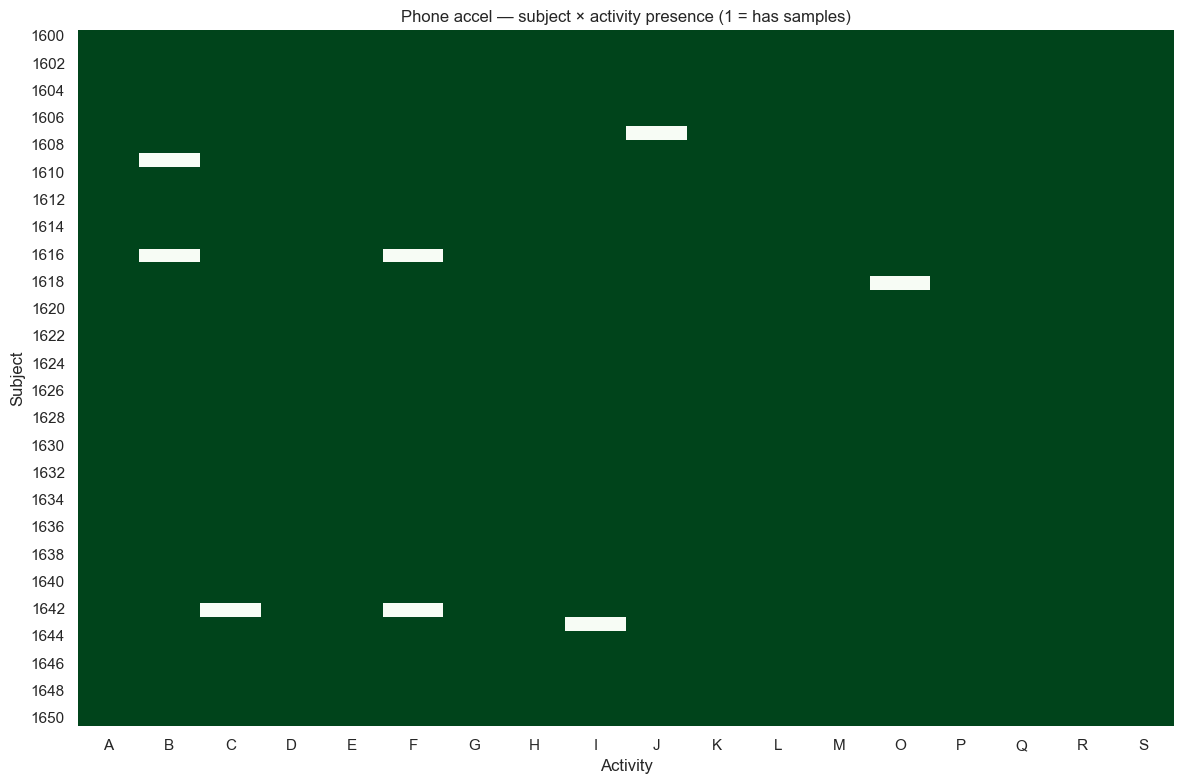

Activities missing for how many subjects (phone accel):


,# subjects missing,name
activity,,
F,2,Typing
B,2,Jogging
J,1,Eating Pasta
C,1,Stairs
O,1,Playing Catch
I,1,Eating Chips
L,0,Eating Sandwich
R,0,Clapping
Q,0,Writing


In [26]:
# subject × activity coverage (phone accel as reference)
cov = (
    act_subj.query("device == 'phone' and sensor == 'accel'")
    .pivot_table(index="subject", columns="activity", values="n", aggfunc="sum", fill_value=0)
)
cov = cov.reindex(columns=ACTIVITY_ORDER, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap((cov > 0).astype(int), cmap="Greens", cbar=False, ax=ax)
ax.set_title("Phone accel — subject × activity presence (1 = has samples)")
ax.set_xlabel("Activity")
ax.set_ylabel("Subject")
plt.tight_layout()
plt.show()

sparse = (cov == 0).sum().sort_values(ascending=False)
print("Activities missing for how many subjects (phone accel):")
display(sparse.rename("# subjects missing").to_frame().assign(name=lambda d: d.index.map(ACTIVITY_MAP)))

A few activties have small number of samples with missing data. We will have to consider an imputation.

## 4. Sampling rate & gaps

,device,sensor,n_files,median_hz_median,median_hz_mean,median_hz_min,median_hz_max,total_gaps_gt_0_5s,files_with_nonmono,total_nan,total_inf
0,phone,accel,51,20.01,30.17,19.86,50.63,512,51,0,0
1,phone,gyro,51,19.86,21.67,19.86,25.28,510,51,0,0
2,watch,accel,51,20.03,22.35,20.00,49.76,519,51,0,0
3,watch,gyro,51,20.03,20.40,20.00,24.82,517,51,0,0


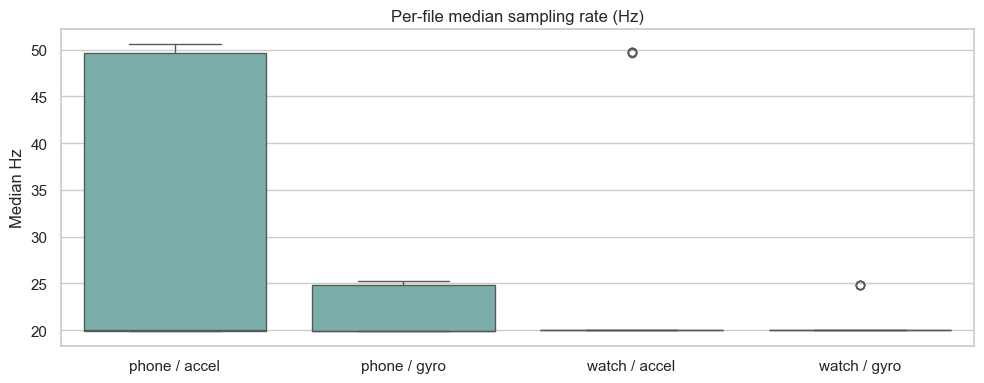

Files with the most large gaps (>0.5s):


,device,sensor,subject,n,median_hz,gap_gt_0_5s,non_monotonic,duration_s
29,phone,accel,1629,139346,19.86,21,14,0.00
131,watch,accel,1629,129808,20.03,21,14,0.00
182,watch,gyro,1629,129738,20.03,21,14,0.00
80,phone,gyro,1629,128500,19.86,21,14,0.00
202,watch,gyro,1649,65131,20.02,14,8,0.00
151,watch,accel,1649,65166,20.02,14,8,0.00
96,phone,gyro,1645,80347,24.81,12,5,0.00
86,phone,gyro,1635,64535,19.86,12,5,4112.97
188,watch,gyro,1635,64858,20.03,12,5,4112.85
35,phone,accel,1635,128852,49.65,12,5,4114.21


In [27]:
hz_summary = (
    files.groupby(["device", "sensor"], as_index=False)
    .agg(
        n_files=("subject", "size"),
        median_hz_median=("median_hz", "median"),
        median_hz_mean=("median_hz", "mean"),
        median_hz_min=("median_hz", "min"),
        median_hz_max=("median_hz", "max"),
        total_gaps_gt_0_5s=("gap_gt_0_5s", "sum"),
        files_with_nonmono=("non_monotonic", lambda s: int((s > 0).sum())),
        total_nan=("n_nan", "sum"),
        total_inf=("n_inf", "sum"),
    )
)
display(hz_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
plot_df = files.copy()
plot_df["stream"] = plot_df["device"] + " / " + plot_df["sensor"]
sns.boxplot(data=plot_df, x="stream", y="median_hz", ax=ax, color="#72B7B2")
ax.set_title("Per-file median sampling rate (Hz)")
ax.set_xlabel("")
ax.set_ylabel("Median Hz")
plt.tight_layout()
plt.show()

print("Files with the most large gaps (>0.5s):")
display(
    files.sort_values("gap_gt_0_5s", ascending=False)[
        ["device", "sensor", "subject", "n", "median_hz", "gap_gt_0_5s", "non_monotonic", "duration_s"]
    ].head(10)
    .round(2)
)

For the majority of subjects, the sensors roughly save 20 samples per second (one every ~50 ms). Nyquist frequency = half of the sampling rate ≈ 10 Hz. That's is the highest frequency we can see for the activity type. Therefore, all spectral plots below are only meaningful from about 0-10 Hz.

## 5. Signal magnitude by activity

Magnitude $mag = \sqrt{x^2 + y^2 + z^2}$. For accel, sedentary activities often sit near ~g; for gyro, near 0 when still.


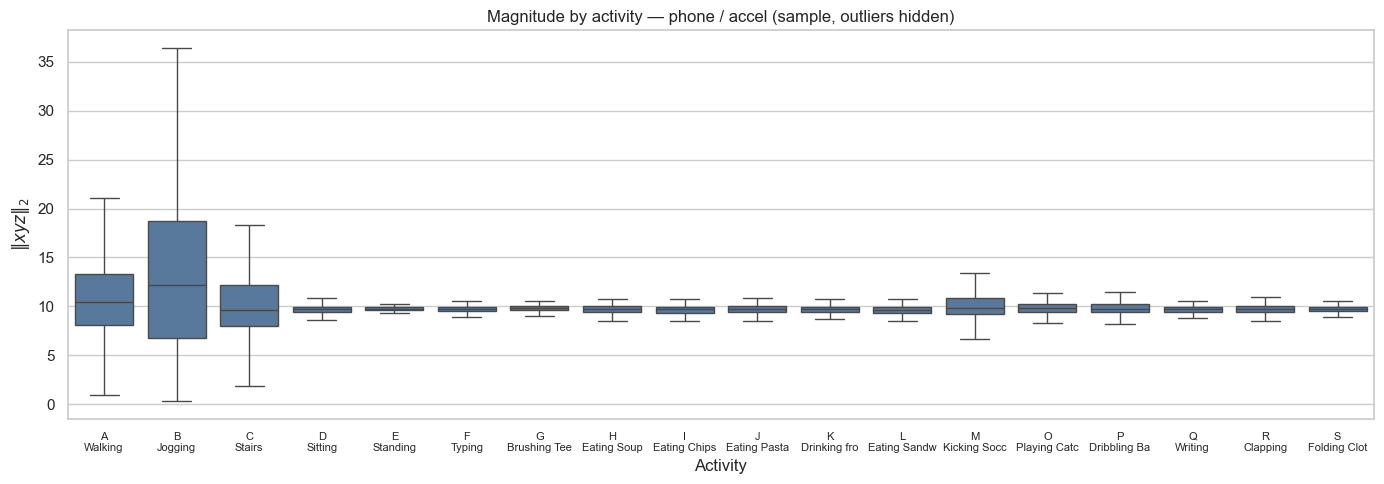

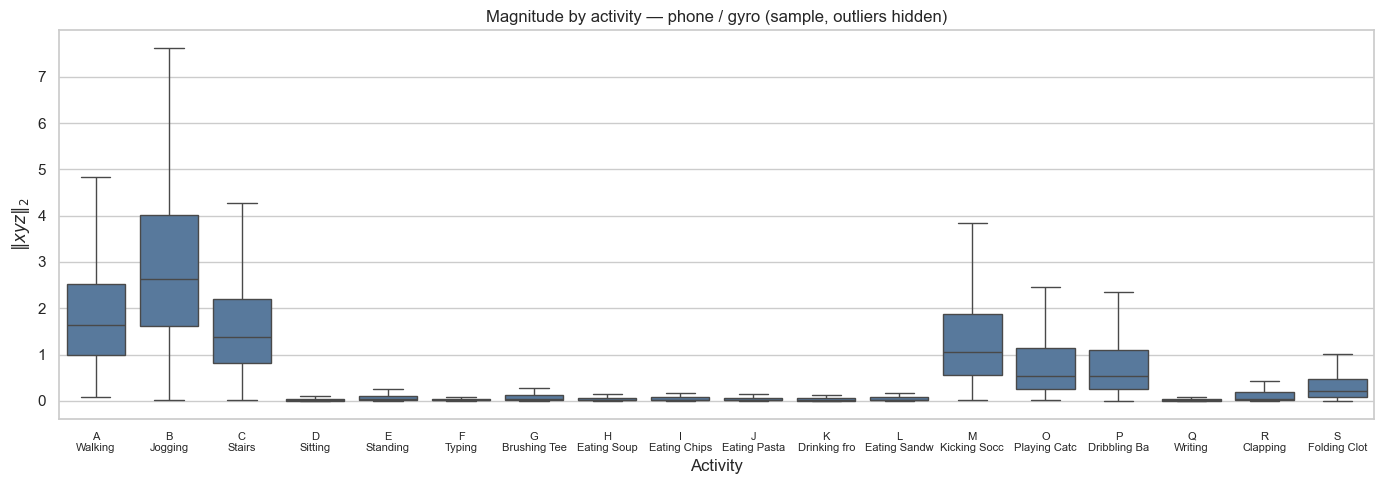

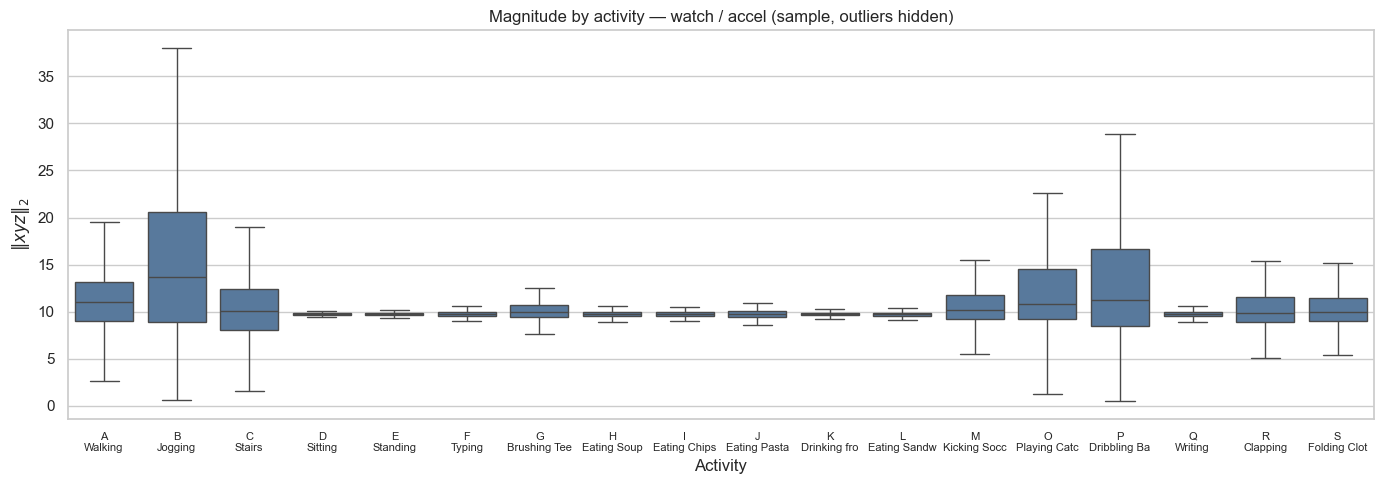

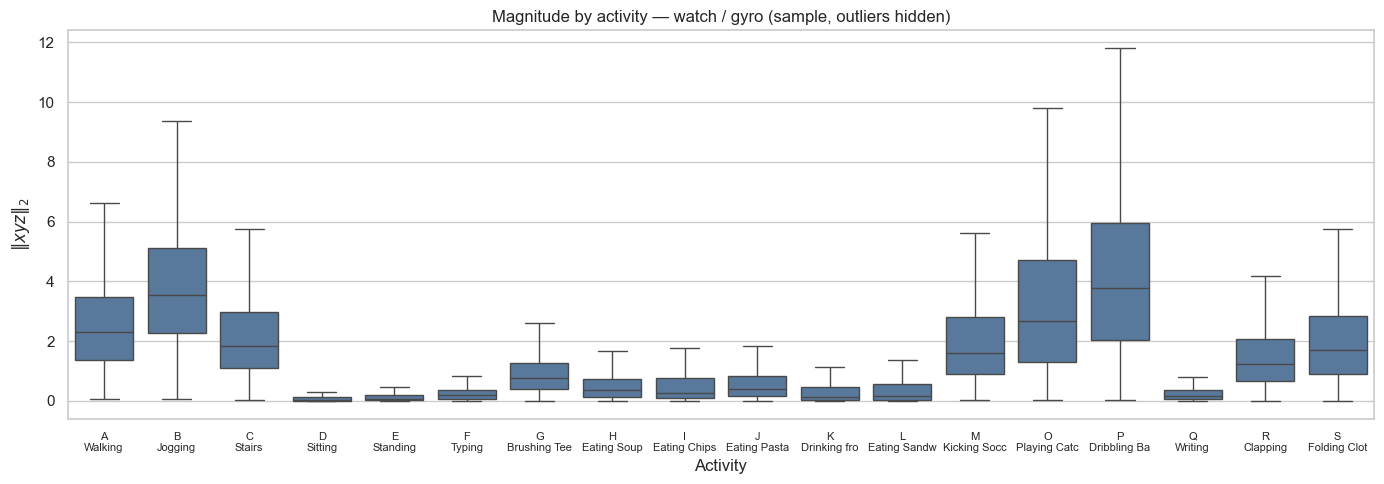

In [28]:
def plot_mag_boxplots(device: str, sensor: str):
    sub = mags_plot.query("device == @device and sensor == @sensor").copy()
    sub["activity"] = pd.Categorical(sub["activity"], categories=ACTIVITY_ORDER, ordered=True)
    sub = sub.sort_values("activity")

    fig, ax = plt.subplots(figsize=(14, 5))
    sns.boxplot(
        data=sub,
        x="activity",
        y="mag",
        showfliers=False,
        ax=ax,
        color="#4C78A8",
    )
    ax.set_title(f"Magnitude by activity — {device} / {sensor} (sample, outliers hidden)")
    ax.set_xlabel("Activity")
    ax.set_ylabel(r"$\|xyz\|_2$")
    present = [c for c in ACTIVITY_ORDER if (sub["activity"] == c).any()]
    ax.set_xticks(range(len(present)))
    ax.set_xticklabels([f"{c}\n{ACTIVITY_MAP[c][:12]}" for c in present], fontsize=8)
    plt.tight_layout()
    plt.show()


for device, sensor in STREAMS:
    plot_mag_boxplots(device, sensor)

As can be seen, magnitude of phone/watch accelerator and gyroscope is around the gravity 9.8 $m/s^2$ and 0 $m/s^2$, respectively, as expected. Larger magnitude denotes a change dependent in activity type. The magnitude can be used as a feature in a tabular table for predicting activity type.

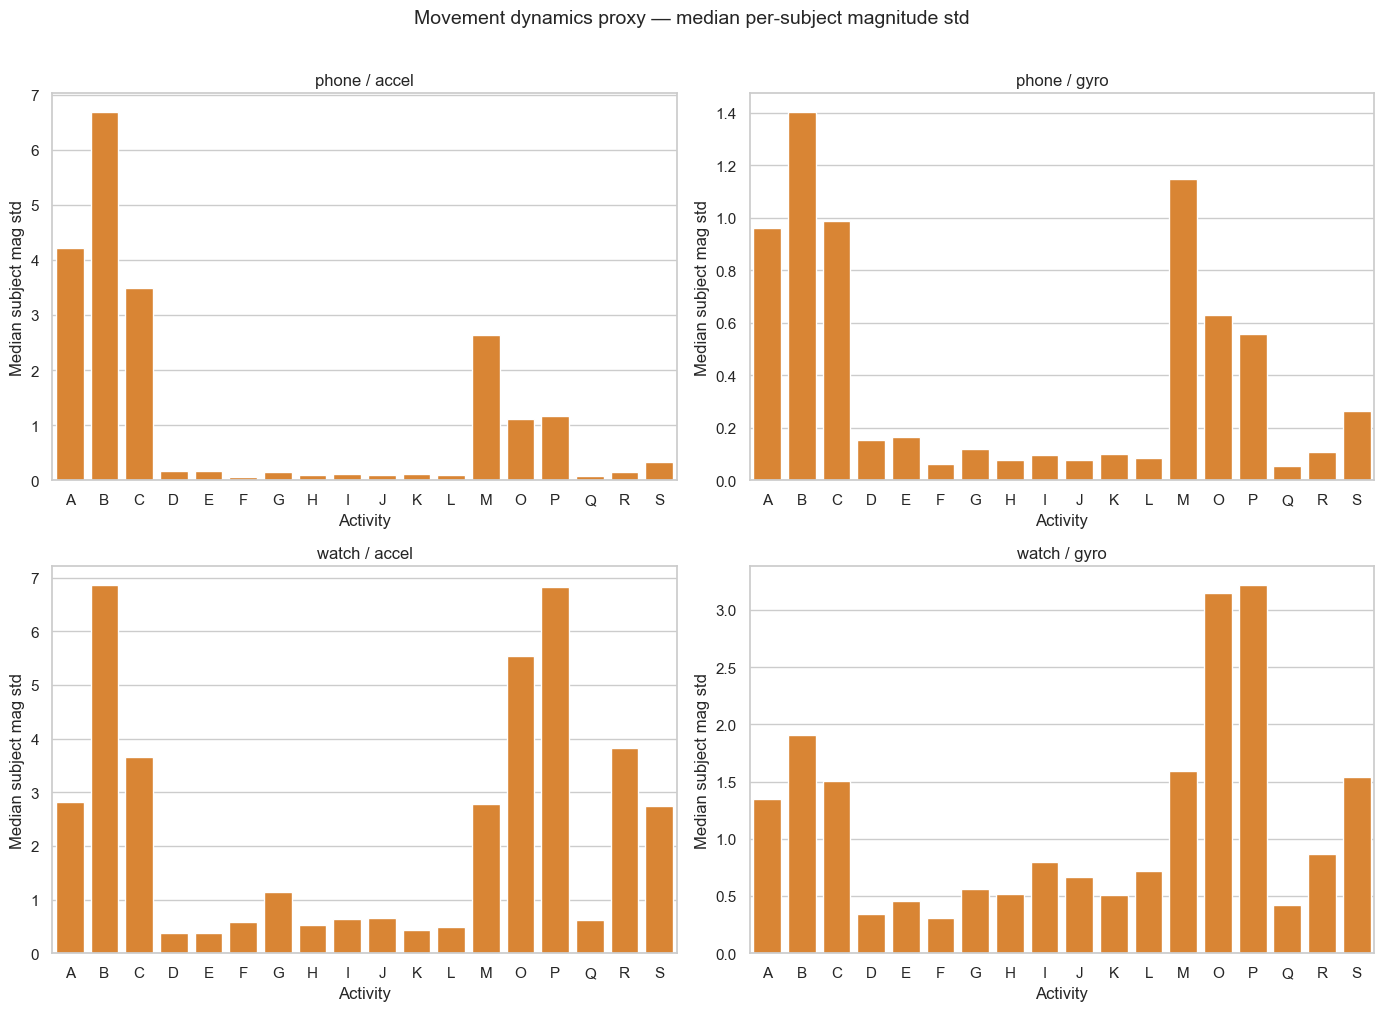

In [29]:
# subject-level summary: mean magnitude std per activity (higher = more movement dynamics)
dyn = (
    act_subj.groupby(["device", "sensor", "activity", "activity_name"], as_index=False)["mag_std"]
    .median()
    .rename(columns={"mag_std": "median_subject_mag_std"})
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=False)
for ax, (device, sensor) in zip(axes.ravel(), STREAMS):
    sub = dyn.query("device == @device and sensor == @sensor").copy()
    sub["activity"] = pd.Categorical(sub["activity"], categories=ACTIVITY_ORDER, ordered=True)
    sub = sub.sort_values("activity")
    sns.barplot(data=sub, x="activity", y="median_subject_mag_std", ax=ax, color="#F58518")
    ax.set_title(f"{device} / {sensor}")
    ax.set_xlabel("Activity")
    ax.set_ylabel("Median subject mag std")
fig.suptitle("Movement dynamics proxy — median per-subject magnitude std", y=1.01, fontsize=14)
fig.tight_layout()
plt.show()

A different way to show how magnitude is changed according to decive, sensor, and activity types. Looking at the y-scale, accelerator magnitudes are larger than the gyro ones. We might want to consider these differences in planning our prediction model. 

## 6. Time-series snippets

Pick one subject and plot raw axes for a few contrasting activities.

Snippet file: data_1600_accel_phone.txt  rows=64,311  activities=['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'O', 'P', 'Q', 'R', 'S']


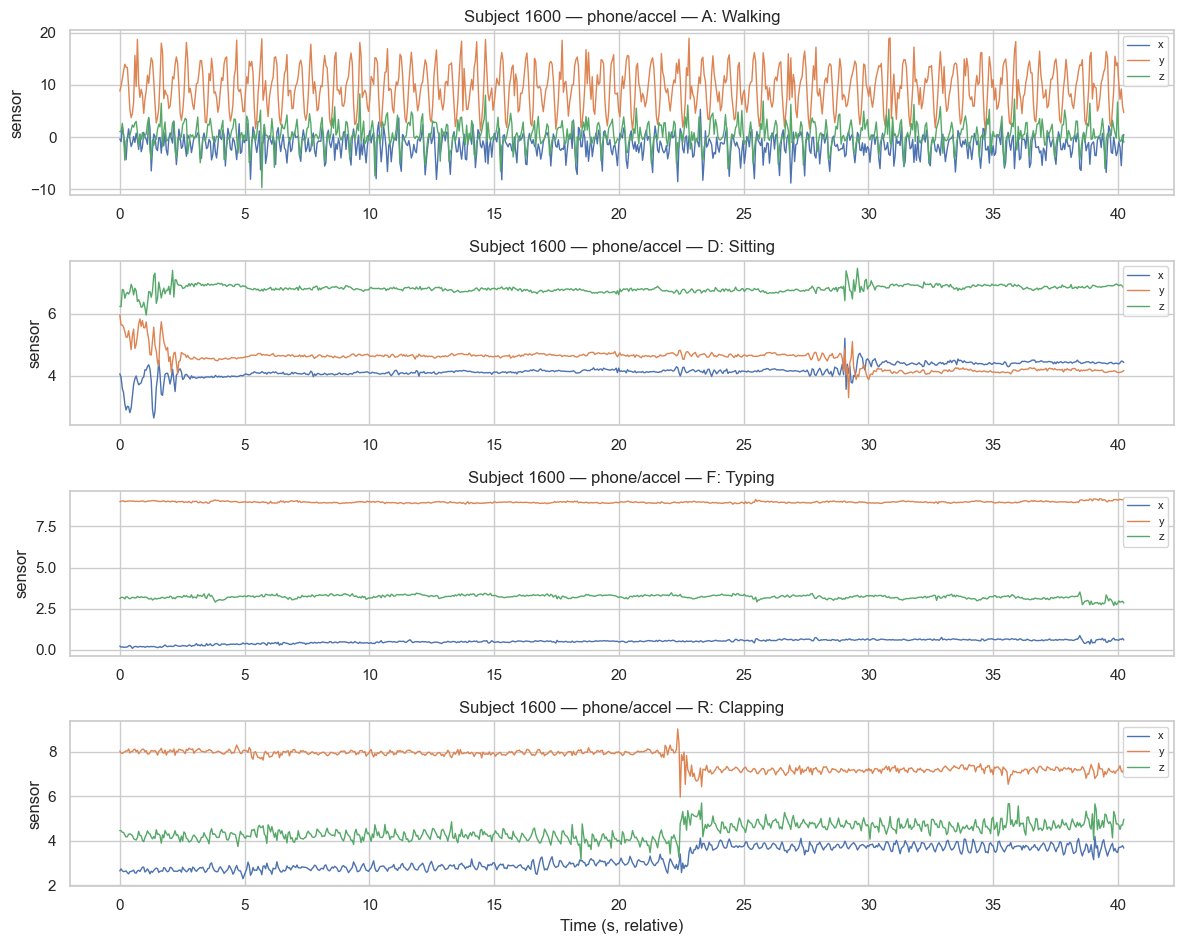

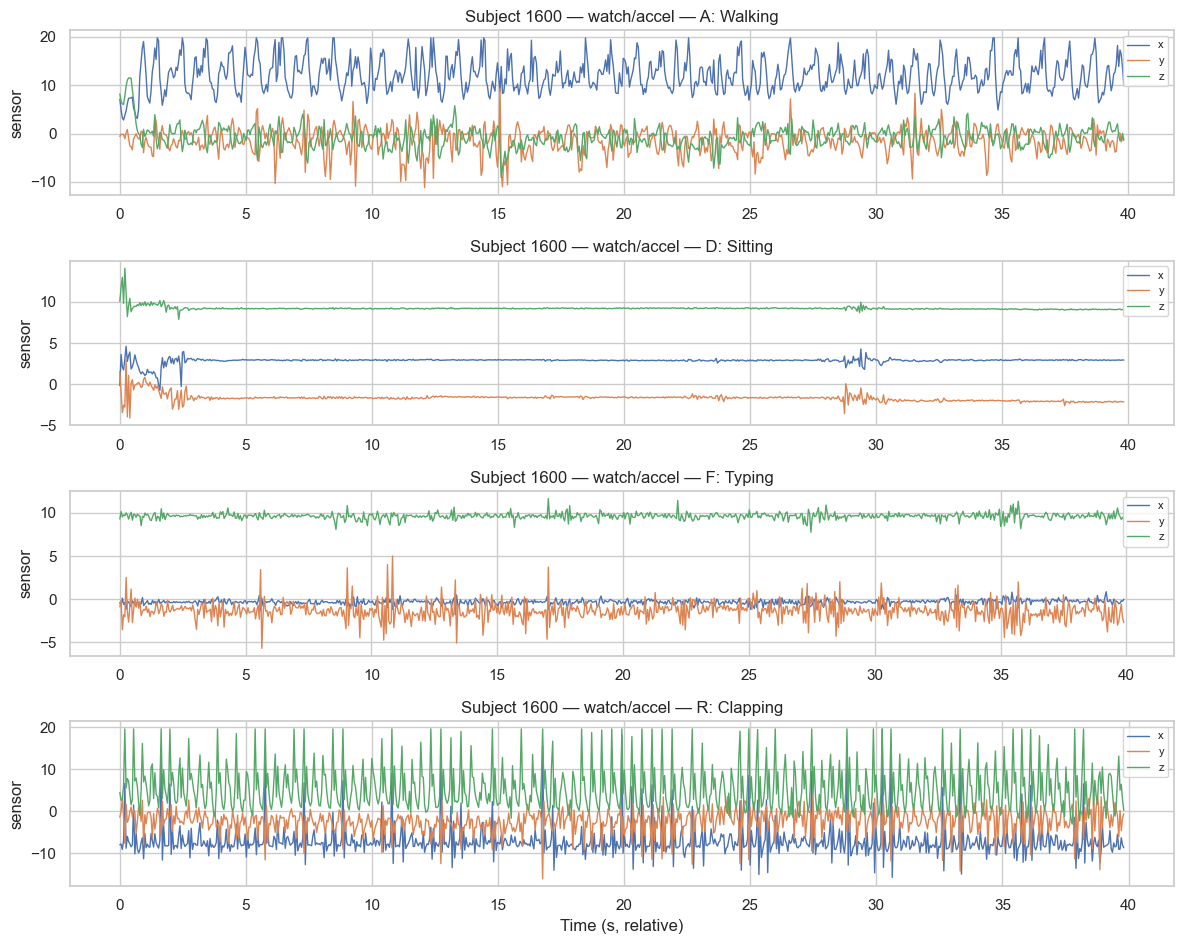

In [30]:
SNIPPET_SUBJECT = int(files["subject"].mode().iloc[0])
SNIPPET_ACTIVITIES = ["A", "D", "F", "R"]  # Walking, Sitting, Typing, Clapping
SNIPPET_STREAM = ("phone", "accel")
MAX_POINTS = 800

device, sensor = SNIPPET_STREAM
path = RAW / device / sensor / f"data_{SNIPPET_SUBJECT}_{sensor}_{device}.txt"
snip = read_sensor_file(path)
print(f"Snippet file: {path.name}  rows={len(snip):,}  activities={sorted(snip['activity'].unique())}")

n_acts = len(SNIPPET_ACTIVITIES)
fig, axes = plt.subplots(n_acts, 1, figsize=(12, 2.4 * n_acts), sharex=False)
if n_acts == 1:
    axes = [axes]

for ax, act in zip(axes, SNIPPET_ACTIVITIES):
    g = snip.loc[snip["activity"] == act].head(MAX_POINTS).copy()
    if g.empty:
        ax.set_title(f"{activity_label(act)} — no data for subject {SNIPPET_SUBJECT}")
        continue
    t0 = g["timestamp"].iloc[0]
    g["t_s"] = (g["timestamp"] - t0) / 1e9
    ax.plot(g["t_s"], g["x"], label="x", lw=1)
    ax.plot(g["t_s"], g["y"], label="y", lw=1)
    ax.plot(g["t_s"], g["z"], label="z", lw=1)
    ax.set_title(f"Subject {SNIPPET_SUBJECT} — {device}/{sensor} — {activity_label(act)}")
    ax.set_ylabel("sensor")
    ax.legend(loc="upper right", fontsize=8)

axes[-1].set_xlabel("Time (s, relative)")
fig.tight_layout()
plt.show()

# optional: same activities on watch accel for contrast
watch_path = RAW / "watch" / "accel" / f"data_{SNIPPET_SUBJECT}_accel_watch.txt"
if watch_path.exists():
    w = read_sensor_file(watch_path)
    fig, axes = plt.subplots(n_acts, 1, figsize=(12, 2.4 * n_acts))
    if n_acts == 1:
        axes = [axes]
    for ax, act in zip(axes, SNIPPET_ACTIVITIES):
        g = w.loc[w["activity"] == act].head(MAX_POINTS).copy()
        if g.empty:
            ax.set_title(f"{activity_label(act)} — no watch data")
            continue
        t0 = g["timestamp"].iloc[0]
        g["t_s"] = (g["timestamp"] - t0) / 1e9
        ax.plot(g["t_s"], g["x"], label="x", lw=1)
        ax.plot(g["t_s"], g["y"], label="y", lw=1)
        ax.plot(g["t_s"], g["z"], label="z", lw=1)
        ax.set_title(f"Subject {SNIPPET_SUBJECT} — watch/accel — {activity_label(act)}")
        ax.set_ylabel("sensor")
        ax.legend(loc="upper right", fontsize=8)
    axes[-1].set_xlabel("Time (s, relative)")
    fig.tight_layout()
    plt.show()

As can be seen, the sensor variables X, Y, Z are informative for activity type and should be considered as features in our prediction model. Also, there is an unsual behavir in the first 2.5 seconds (and in 28-30 seconds) in sitting activity type, suggesting the movement from standing to sitting (or jumping/chaning pose on the sit). We might want to extend the prediction time interval from 5 to 10 seconds to reduce such random noise cases. 

## 7. Spectral analysis (Welch PSD + spectrograms)

Sampling is roughly **~20 Hz**, so Nyquist is ~10 Hz. Useful content for locomotion sits in the low-Hz band (e.g. walking cadence ~1.5–2.5 Hz). We estimate **fs from each activity segment’s median Δt**, then:
1. Average Welch PSD of magnitude by activity (phone + watch accel)
2. Dominant frequency (peak of PSD) per subject×activity
3. Example spectrograms for contrasting activities


In [31]:
from scipy import signal

MIN_SEGMENT_SAMPLES = 64  # skip tiny chunks for PSD
WELCH_NPERSEG = 128
N_SUBJECTS_PSD = 12  # average PSD over a subset of subjects for speed


def segment_magnitude(df: pd.DataFrame, activity: str) -> tuple[np.ndarray, float] | tuple[None, None]:
    """Return (mag, fs_hz) for one contiguous-ish activity block (first run)."""
    g = df.loc[df["activity"] == activity, ["timestamp", "x", "y", "z"]]
    if len(g) < MIN_SEGMENT_SAMPLES:
        return None, None
    # take the longest contiguous run (activity may appear more than once)
    act_mask = (df["activity"] == activity).to_numpy()
    # find runs in full file order
    idx = np.flatnonzero(act_mask)
    # split where index gaps > 1
    breaks = np.where(np.diff(idx) > 1)[0]
    runs = np.split(idx, breaks + 1)
    best = max(runs, key=len)
    if len(best) < MIN_SEGMENT_SAMPLES:
        return None, None
    block = df.iloc[best]
    ts = block["timestamp"].to_numpy(dtype=np.float64)
    dt = np.diff(ts)
    dt = dt[dt > 0]
    if dt.size == 0:
        return None, None
    fs = float(1e9 / np.median(dt))
    mag = np.sqrt(block["x"].to_numpy() ** 2 + block["y"].to_numpy() ** 2 + block["z"].to_numpy() ** 2)
    # remove DC for clearer spectral peaks
    mag = mag - mag.mean()
    return mag, fs


def welch_psd(mag: np.ndarray, fs: float) -> tuple[np.ndarray, np.ndarray]:
    nperseg = min(WELCH_NPERSEG, len(mag) // 2)
    nperseg = max(nperseg, 16)
    freqs, psd = signal.welch(mag, fs=fs, nperseg=nperseg)
    return freqs, psd


def dominant_freq(mag: np.ndarray, fs: float) -> float:
    freqs, psd = welch_psd(mag, fs)
    # ignore very near-DC bin
    keep = freqs >= 0.2
    if not keep.any():
        return float("nan")
    return float(freqs[keep][np.argmax(psd[keep])])


print("Spectral helpers ready.")


Spectral helpers ready.


In [32]:
# Average Welch PSD of magnitude by activity (phone accel & watch accel)
SPECTRAL_STREAMS = [("phone", "accel"), ("watch", "accel")]
subjects_for_psd = sorted(files["subject"].unique())[:N_SUBJECTS_PSD]

psd_curves = []  # rows: device, sensor, activity, freq, psd
dom_rows = []

for device, sensor in SPECTRAL_STREAMS:
    for subject in tqdm(subjects_for_psd, desc=f"PSD {device}/{sensor}"):
        path = RAW / device / sensor / f"data_{subject}_{sensor}_{device}.txt"
        if not path.exists():
            continue
        df = read_sensor_file(path)
        for act in ACTIVITY_ORDER:
            mag, fs = segment_magnitude(df, act)
            if mag is None:
                continue
            freqs, psd = welch_psd(mag, fs)
            # interpolate onto a common 0–min(8, Nyquist*0.95) Hz grid for averaging
            f_max = min(8.0, 0.95 * (fs / 2))
            f_grid = np.linspace(0.0, f_max, 80)
            psd_i = np.interp(f_grid, freqs, psd)
            for f, p in zip(f_grid, psd_i):
                psd_curves.append(
                    {"device": device, "sensor": sensor, "activity": act, "freq_hz": f, "psd": p, "subject": subject}
                )
            dom_rows.append(
                {
                    "device": device,
                    "sensor": sensor,
                    "subject": subject,
                    "activity": act,
                    "fs_hz": fs,
                    "dominant_hz": dominant_freq(mag, fs),
                    "n": len(mag),
                }
            )

psd_df = pd.DataFrame(psd_curves)
dom_df = pd.DataFrame(dom_rows)
dom_df["activity_name"] = dom_df["activity"].map(ACTIVITY_MAP)

print(f"PSD curve points: {len(psd_df):,}  |  dominant-freq rows: {len(dom_df):,}")
display(dom_df.groupby(["device", "sensor"])["fs_hz"].describe()[["count", "mean", "50%", "min", "max"]].round(2))


PSD phone/accel:   0%|          | 0/12 [00:00<?, ?it/s]

PSD watch/accel:   0%|          | 0/12 [00:00<?, ?it/s]

PSD curve points: 34,400  |  dominant-freq rows: 430


,,count,mean,50%,min,max
device,sensor,,,,,
phone,accel,214.0,23.39,19.86,19.86,49.65
watch,accel,216.0,20.77,20.03,20.01,100.49


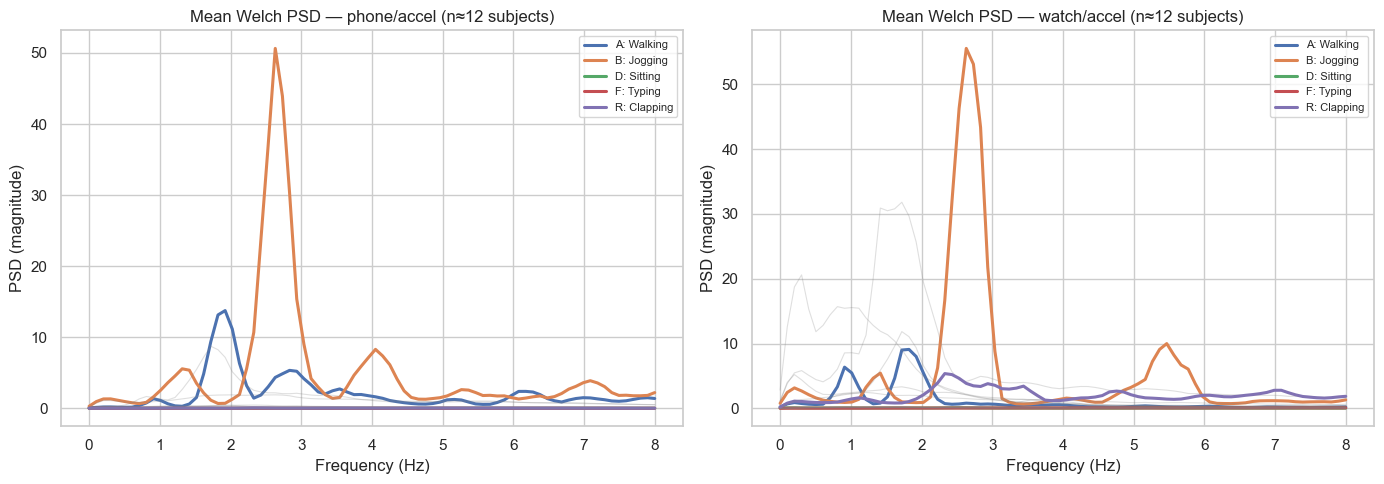

In [33]:
# Mean PSD curves by activity
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, (device, sensor) in zip(axes, SPECTRAL_STREAMS):
    sub = psd_df.query("device == @device and sensor == @sensor")
    mean_psd = (
        sub.groupby(["activity", "freq_hz"], as_index=False)["psd"]
        .mean()
    )
    # highlight a few activities; show others faint
    highlight = {"A": "Walking", "B": "Jogging", "D": "Sitting", "F": "Typing", "R": "Clapping"}
    for act in ACTIVITY_ORDER:
        g = mean_psd.loc[mean_psd["activity"] == act]
        if g.empty:
            continue
        if act in highlight:
            ax.plot(g["freq_hz"], g["psd"], lw=2.2, label=f"{act}: {highlight[act]}")
        else:
            ax.plot(g["freq_hz"], g["psd"], lw=0.8, alpha=0.25, color="0.5")
    ax.set_title(f"Mean Welch PSD — {device}/{sensor} (n≈{N_SUBJECTS_PSD} subjects)")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (magnitude)")
    ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()


Power Spectral Density (PSD) measures the energy in each frequency per activity type. Here, the frequencies of the maximum average energy (n=12 subjects) for walking and jogging are ~1.9 Hz and ~2.6 Hz, respectivly. Therefore, such Dominant PSD frequencies can be used as features in the predcition model. Dominant frequencies are shown below.

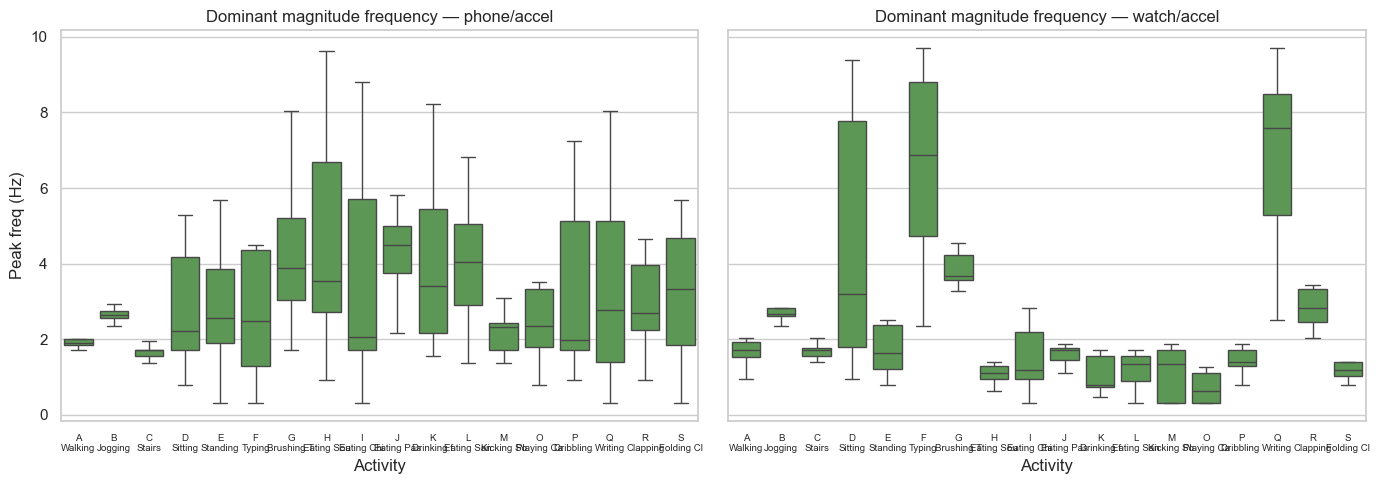

Median dominant frequency (Hz) by activity — phone accel:


,activity,activity_name,dominant_hz
0,A,Walking,1.901
1,B,Jogging,2.638
2,C,Stairs,1.707
3,D,Sitting,2.220
4,E,Standing,2.560
5,F,Typing,2.493
6,G,Brushing Teeth,3.879
7,H,Eating Soup,3.546
8,I,Eating Chips,2.065
9,J,Eating Pasta,4.499


In [35]:
# Dominant frequency by activity (boxplots)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (device, sensor) in zip(axes, SPECTRAL_STREAMS):
    sub = dom_df.query("device == @device and sensor == @sensor").copy()
    sub["activity"] = pd.Categorical(sub["activity"], categories=ACTIVITY_ORDER, ordered=True)
    sub = sub.sort_values("activity")
    sns.boxplot(data=sub, x="activity", y="dominant_hz", showfliers=False, ax=ax, color="#54A24B")
    ax.set_title(f"Dominant magnitude frequency — {device}/{sensor}")
    ax.set_xlabel("Activity")
    ax.set_ylabel("Peak freq (Hz)")
    present = [c for c in ACTIVITY_ORDER if (sub["activity"] == c).any()]
    ax.set_xticks(range(len(present)))
    ax.set_xticklabels([f"{c}\n{ACTIVITY_MAP[c][:10]}" for c in present], fontsize=7)
fig.tight_layout()
plt.show()

print("Median dominant frequency (Hz) by activity — phone accel:")
display(
    dom_df.query("device == 'phone' and sensor == 'accel'")
    .groupby(["activity", "activity_name"], as_index=False)["dominant_hz"]
    .median()
    .sort_values("activity")
    .round(3)
)


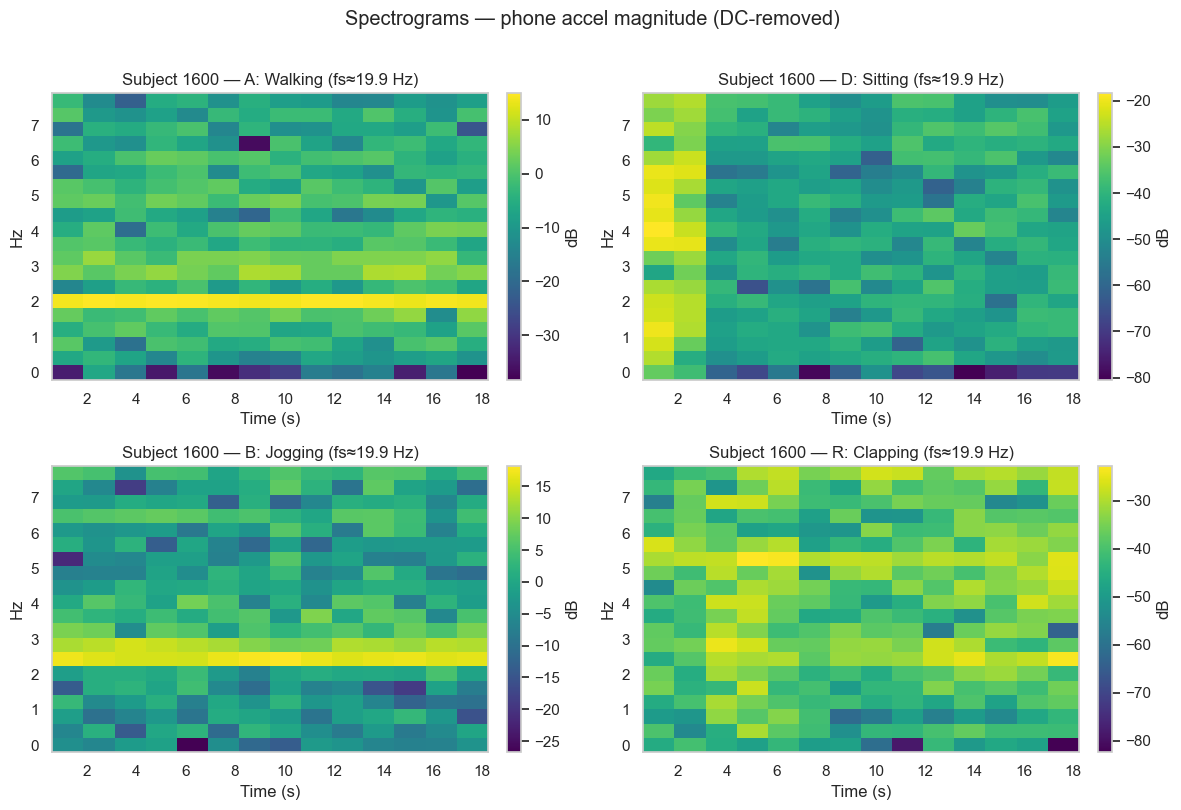

In [36]:
# Spectrograms for contrasting activities (one subject, phone accel)
SPEC_SUBJECT = int(dom_df["subject"].mode().iloc[0]) if len(dom_df) else SNIPPET_SUBJECT
SPEC_ACTIVITIES = ["A", "D", "B", "R"]  # Walking, Sitting, Jogging, Clapping
spec_path = RAW / "phone" / "accel" / f"data_{SPEC_SUBJECT}_accel_phone.txt"
spec_df = read_sensor_file(spec_path)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, act in zip(axes.ravel(), SPEC_ACTIVITIES):
    mag, fs = segment_magnitude(spec_df, act)
    if mag is None:
        ax.set_title(f"{activity_label(act)} — insufficient data")
        continue
    # use up to ~20 s for a readable spectrogram
    max_n = int(min(len(mag), fs * 20))
    mag = mag[:max_n]
    nperseg = min(64, max(16, max_n // 8))
    f, t, Sxx = signal.spectrogram(mag, fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
    # clip to <= 8 Hz for readability
    keep = f <= 8
    pcm = ax.pcolormesh(t, f[keep], 10 * np.log10(Sxx[keep] + 1e-12), shading="auto", cmap="viridis")
    ax.set_title(f"Subject {SPEC_SUBJECT} — {activity_label(act)} (fs≈{fs:.1f} Hz)")
    ax.set_ylabel("Hz")
    ax.set_xlabel("Time (s)")
    fig.colorbar(pcm, ax=ax, fraction=0.046, pad=0.04, label="dB")
fig.suptitle("Spectrograms — phone accel magnitude (DC-removed)", y=1.01)
fig.tight_layout()
plt.show()


We can see that the spectograms are different for every activity type. In sitting type, the large energy in the first 2.5 seonds is probably due to switching from standing to sitting. 

## Summary

1. Subject **1629** has duplicated rows that need to be removed.
2. subject **1649** watch streams have some timestamp collisions across activity labels.
3. No class imbalance between activities.
4. A few activities with missing subject data - imputation should be considered (Maybe using kNN to find related subjects)
5. X, Y, Z, magnitude, dominant PSD frequency, device, sensor - can be used as features in a tabular data to predict activity type.
6. Option to recommend users based on activity type - sort users based on predicted activity (class) probabilities
7. Activity type prediction for each time interval (5-10 seconds). The larger the time interval the more reliable the activity signal.